# Lab 4 bis: **Invariance** in a *shallow FCN* under data augmentation

Advanced Topics in Machine Learning -- Fall 2025, UniTS

<a target="_blank" href="https://colab.research.google.com/github/ganselmif/adv-ml-units/blob/main/notebooks/AdvML_UniTS_2025_Lab_04bis_FCN_Invariance.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"/></a>

#### High-level overview

In this *Lab*, we will understand how the effect of *data augmentation* (whose effect on learned **weights** has been analyzed in the previous lab) translates to the **representation** learned by the model.

Specifically, we define *representation* the (ordered) set of activations of a *neural network* model, which is dependent on the input, and can be seen as the way the model *sees* the data as a result of the learning process.

To accomplish this goal, we will:

- Load the weights resulting from the training of the model described in the previous lab;
- Learn how to extract the activations of a given layer of the model, in response to a given input;
- Evaluate such activations on mutually-rotated versions of the same input, and compare such activations to assess their *invariance*  with respect to the transformation.

#### Preliminary: adapt and re-run the previous notebook

Before starting to delve into this lab, you should:
- Go back to the previous *Lab* notebook;
- Add the (single line of) code required to save the model weights after training;
- Re-run the notebook, to make sure that the weights are saved correctly;


#### (Re-)definition of the model

Define the exact same model you used in the previous lab, and instantiate it.

In [25]:
import torch
from torch import Tensor
import torchvision
import numpy as np

import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import DataLoader

from torchvision import datasets
from torchvision import transforms

import matplotlib.pyplot as plt

from tqdm import trange

In [26]:
class ShallowFCN(nn.Module):

    def __init__(self):
        super(ShallowFCN, self).__init__()

        self.l1 = nn.Linear(in_features=28*28, out_features=10, bias=False)
        
    def forward(self, x : Tensor):
        x = self.l1(x.flatten(start_dim=1))
        return F.softmax(x, dim=1)

#### Weights loading

Load into the instance of your model the weights you just saved from the adapted notebook.

In [27]:
model = torch.load("model_4.pth", weights_only=False)

#### Data preparation

To test for a given transformation invariance, you should have pairs of (test) data obtained from the same image: one original, and one transformed.

**Hint**: if you want to offload the task to already implemented `torchvision.transforms`, notice (to your advantage) that -- since we are just testing the model -- the dataset needs not to be in shuffled order!


In [28]:
BATCH_SIZE: int = 32

data_transforms = transforms.Compose((transforms.ToTensor(), transforms.Normalize(mean=0.1307, std=0.3081)))
data_transforms_plus_rotation = transforms.Compose((transforms.ToTensor(), transforms.RandomRotation((0, 180)), transforms.Normalize(mean=0.1307, std=0.3081)))

test_dataset = datasets.MNIST(root="./data", train=False, transform=data_transforms, download=True)
rotated_test_dataset = datasets.MNIST(root="./data", train=False, transform=data_transforms_plus_rotation, download=True)

test_loader = DataLoader(dataset=test_dataset, batch_size=BATCH_SIZE, shuffle=False)
rotated_test_loader = DataLoader(dataset=rotated_test_dataset, batch_size=BATCH_SIZE, shuffle=False)

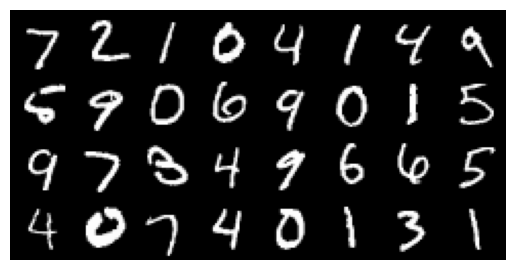

In [29]:
def imshow(img) -> None:
    npimg = img.numpy()
    plt.axis("off")
    plt.imshow(np.transpose(npimg, axes=(1, 2, 0)))

# Non-Rotated
dataiter = test_loader.__iter__()
images, labels = dataiter.__next__()

imshow(torchvision.utils.make_grid(images, normalize=True))

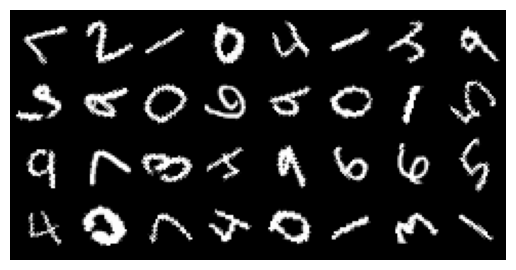

In [30]:
# Rotated
dataiter = rotated_test_loader.__iter__()
images, labels = dataiter.__next__()

imshow(torchvision.utils.make_grid(images, normalize=True))

#### Activation extraction

Write a function that extracts the activations of a given layer of the model, in response to a given input. Try to remain as generic as possible, since you may need to re-use it in the future.

**Hint**: Look up in the documentation the purpose and features of `hook`s. If you are in trouble, just ask!


In [31]:
# YOUR CODE HERE
def get_activations(model, x):

    def activation_hook(module, input, output):
        activation['l1'] = output.detach()

    activation = {}
    hook_handle = model.l1.register_forward_hook(activation_hook)
    _ = model(x)
    hook_handle.remove()
    return activation['l1']

#### Invariance evaluation

Recall the definition of *invariance* of (the result of) function $f$ with respect to transformation $g(\cdot\;; \alpha)$ parametrized by $\alpha$:

$$f(g(x; \alpha))=f(x)\;\;\;\; \forall\alpha$$

With the function and data just defined, compare in a statistically-significant manner the activations of the model on the original and transformed versions of the same image. Comment on the results.


In [32]:
differences = []

model.to("cpu")

for i, (images, labels) in enumerate(test_loader):

    (images_rot, labels_rot) = rotated_test_loader.__iter__().__next__()

    activation = get_activations(model, images)
    rotated_activation = get_activations(model, images_rot)

    # because rotated one are filled so that they can mismatch 
    if activation.shape[0] != rotated_activation.shape[0]:
        rotated_activation = rotated_activation[: activation.shape[0]]

    differences.append(activation - rotated_activation)

average_difference = torch.linalg.norm(torch.cat(differences, dim=0), dim=1).mean()
print(f"Average difference in activation: {average_difference}")

Average difference in activation: 12.919833183288574
